# A brief tutorial 

In [1]:
import time
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

from pynav.agents import QAgent
from pynav.environment import Environment as Env

## Data Loading

In [2]:
data = np.load("/storage/rando/data/nose_data_27_123.npy") # replace with your data path

n_thr = 3e-6 
data[data < n_thr] = 0.0


In [3]:
print(data.max())

0.0014944219105691057


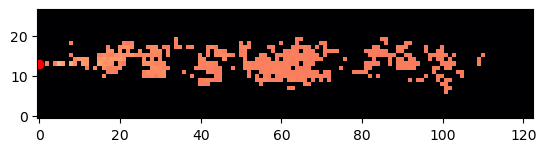

In [4]:
log_data = data.copy()
log_data[log_data == 0.0] = 1e-20

fig, ax = plt.subplots()
ax.imshow(np.log10(log_data[0, :, :]), cmap='magma', origin='lower', vmax=log_data.max())
ax.plot(0.0, 13.0, 'o', c='red')


Firstly, we create an environment specifing the data, the source position and the rewards

In [65]:
source_radius = 2
velocity = 1
rewards = (1.0, 0.0)
seed = 12131415

env = Env(data = data, 
          source_position=np.array([14, 0]), 
          source_radius = source_radius, 
          boundary_conditions = None,
          seed=seed,
          rewards = rewards)

print(env.source_reached(np.array([16, -1])))


False


Now, we specify the action set (in this example, we will use the coordinate directions)

In [66]:
actions = {
    0 : np.asarray([ 1, 0], dtype=np.int32), 
    1 : np.asarray([-1, 0], dtype=np.int32), 
    2 : np.asarray([0,  1], dtype=np.int32), 
    3 : np.asarray([0, -1], dtype=np.int32), 
}

action_labels = ['up', 'down', 'right', 'left']


In [67]:
pmap = np.load("/home/arnaud/POMDP_PBVI_Exploration/Experiments/Olfactory Navigation/Data/statistics_nose_3e6_27_123.npy")

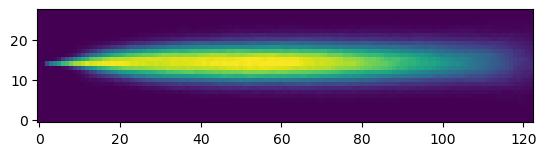

In [75]:
fig, ax = plt.subplots()
ax.imshow(pmap, origin='lower')

In [102]:
#self.init_value * np.exp(-self.decay * self.num_episode)
# DO NOT CHANGE!
eps_decay = 0.00005
alpha_decay = 0.0001
eps = lambda t :  np.exp(-eps_decay * t)  
alpha = lambda t : 1.0 * np.exp(-alpha_decay * t)  #if 0.3 * np.exp(-alpha_decay * t) > 0.001 else 0.001

agent = QAgent(
    number_of_actions = 4,
    time_discretization_size = 300,
    memory_size = 10,
    eps_greedy = eps,
    gamma = 1.0,
    learning_rate = alpha,
    s_thr = 3e-6
)

In [103]:
start_points = (pmap > 0.0).astype(np.float64)

start_points /= np.sum(start_points)
start_points = start_points.ravel()

In [104]:
H = 400 # horizon
num_episodes = 100000
rnd_state = np.random.RandomState(12131415)
q_prev = None
cumulative_rewards = []
average_crewards = []
num_steps = []
delta_size = 500
k = 0
iterator = tqdm(range(num_episodes))
for k in iterator:
    # Initialization
    agent.reset()
    pos_idx = rnd_state.choice(range(start_points.shape[0]), 1, p=start_points)
    pos_y, pos_x = np.unravel_index(pos_idx, shape=pmap.shape)
    pos = np.concatenate([pos_y, pos_x])
    if env.source_reached(pos):
        continue
    time_idx = rnd_state.randint(0, env.MAX_T)
    obs = env.get_observation(pos, time_idx)
    time_idx = time_idx % env.MAX_T
    s = agent.update_state(obs) # update memory and compute olfactory state
    trace = []
    if q_prev is None:
        q_prev = agent.Q.copy()
    c_reward = 0.0
    for t in range(H):
        a = agent.select_action()
        pos, r, terminated = env.make_move(pos, actions[a])
        obs = env.get_observation(pos, time_idx)
        time_idx = (time_idx + 1) % env.MAX_T
        s_prime = agent.update_state(obs)
        c_reward += r * (agent.gamma**t) if t > 0 else r
        trace.append((s, a, s_prime, r))
        if terminated:
            break
        s = s_prime
        num_steps.append(t + 1)
    agent.update_q(trace)
    cumulative_rewards.append(c_reward)
    q_prev = agent.Q.copy()
    iterator.set_postfix({'avg R_t' : np.mean(cumulative_rewards[-delta_size:]), 
                          'eps' : f'{agent.eps_greedy(agent.num_episode)}',
                          'alpha' : f'{agent.learning_rate(agent.num_episode)}'})
    average_crewards.append(np.mean(cumulative_rewards[-delta_size:]))


100%|██████████| 10000/10000 [02:35<00:00, 64.20it/s, avg R_t=0.116, eps=0.6068036599299461, alpha=0.36821068170437765]


Text(0.5, 0, 'episodes')

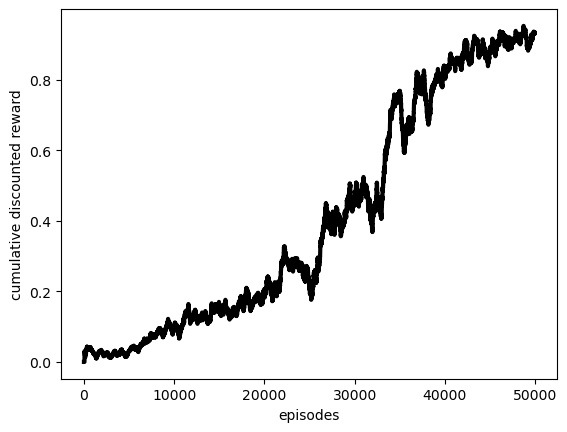

In [93]:
fig, ax = plt.subplots()
ax.plot(range(len(average_crewards)), average_crewards, '-', c='black', lw=3)

ax.set_ylabel("cumulative discounted reward")
ax.set_xlabel("episodes")


We can store the computed Q-table using `store_q` function

In [40]:
agent.store_q("./q_trained_200")

In [62]:
agent.reset()
init_pos = np.array([10, 120])
time_idx = 1#(time_idx + 1) % env.MAX_T
obs = env.get_observation(pos, time_idx)
s = agent.update_state(obs) # update memory and compute olfactory state
trace = []
source_pos = np.array([14.0, 0.0])
c_reward = 0.0
pos = init_pos.copy()
iterator = tqdm(range(H))
for t in iterator:
    a = agent.select_action()
    pos, r, terminated = env.make_move(pos, actions[a])
    obs = env.get_observation(pos, time_idx)
    time_idx = (time_idx + 1) % env.MAX_T
    s_prime = agent.update_state(obs)
    c_reward += r * (agent.gamma**t) if t > 0 else r
    trace.append((s, a, s_prime, r))
    if terminated:
        T_min = np.abs(source_pos[0] - init_pos[0]) + np.abs(source_pos[1] - init_pos[1]) - 3
        iterator.set_postfix({f"Converged! steps" : f"{t} steps", "T_min / T " : T_min / t})
        break
    s = s_prime


 45%|████▍     | 179/400 [00:00<00:00, 20585.12it/s, Converged! steps=179 steps, T_min / T =0.676]


Test agent for every test point at a given time slice

In [98]:
time_slice = 0
iterator = tqdm(range(start_points.shape[0]))
num_converged = 0
num_valid_pos = 0

for pos_idx in iterator:
    pos_y, pos_x = np.unravel_index(np.array([pos_idx]), shape=pmap.shape)
    init_pos = np.concatenate([pos_y, pos_x])
    if env.source_reached(init_pos):
        continue
    num_valid_pos += 1
    agent.reset()
    time_idx = time_slice
    obs = env.get_observation(pos, time_idx)
    s = agent.update_state(obs) # update memory and compute olfactory state
    trace = []
    source_pos = np.array([14.0, 0.0])
    c_reward = 0.0
    pos = init_pos.copy()
    #iterator = tqdm(range(H))
    T_ratio = []
    for t in range(H):
        a = agent.select_action()
        pos, r, terminated = env.make_move(pos, actions[a])
        obs = env.get_observation(pos, time_idx)
        time_idx = (time_idx + 1) % env.MAX_T
        s_prime = agent.update_state(obs)
        c_reward += r * (agent.gamma**t) if t > 0 else r
        trace.append((s, a, s_prime, r))
        if terminated:
            T_min = np.abs(source_pos[0] - init_pos[0]) + np.abs(source_pos[1] - init_pos[1]) - 2
            iterator.set_postfix({f"Converged! steps" : f"{t} steps", "T_min / T " : T_min / (t + 1)})
            T_ratio.append(T_min / (t + 1))
            num_converged +=1
            break
        s = s_prime


100%|██████████| 3444/3444 [00:12<00:00, 264.98it/s, Converged! steps=380 steps, T_min / T =0.349] 


In [100]:
num_converged / num_valid_pos, np.mean(T_ratio)

(0.9170305676855895, 0.34908136482939633)

In [37]:

num_up, num_down = 0, 0
for i in range(agent.Q.shape[0]):
    print("[--] state = {}\taction = {}\tQ-values = {}".format(i, action_labels[np.argmax(agent.Q[i])], agent.Q[i] ))
    if action_labels[np.argmax(agent.Q[i])] == 'up':
        num_up += 1
    if action_labels[np.argmax(agent.Q[i])] == 'down':
        num_down += 1

[--] state = 0	action = left	Q-values = [0.8538458 0.8514689 0.85075   0.8665859]
[--] state = 1	action = left	Q-values = [0.6922865  0.69255954 0.68522704 0.7176339 ]
[--] state = 2	action = down	Q-values = [0.6865037  0.70514685 0.67851996 0.68803847]
[--] state = 3	action = left	Q-values = [0.6749617  0.67838144 0.67270607 0.6978792 ]
[--] state = 4	action = left	Q-values = [0.6689925  0.67336553 0.66539    0.68959403]
[--] state = 5	action = down	Q-values = [0.66290843 0.6801078  0.65697825 0.66986763]
[--] state = 6	action = left	Q-values = [0.65310127 0.6590288  0.65203404 0.67091715]
[--] state = 7	action = down	Q-values = [0.6507516  0.66612417 0.64853925 0.6529831 ]
[--] state = 8	action = left	Q-values = [0.64478916 0.6483936  0.6429027  0.66230464]
[--] state = 9	action = down	Q-values = [0.6396801  0.65841955 0.6356934  0.6439843 ]
[--] state = 10	action = down	Q-values = [0.63188154 0.65303177 0.6322755  0.6336024 ]
[--] state = 11	action = down	Q-values = [0.6293947  0.64

In [17]:
num_up, num_down

(24, 28)

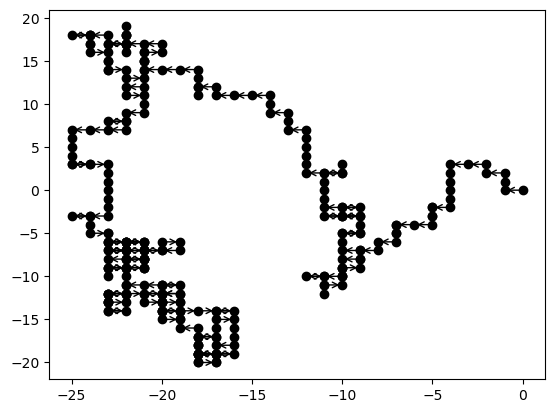

In [101]:
pos = np.array([0, 0])

path = [pos.copy()]
for i in range(1, agent.Q.shape[0]):
    pos += actions[np.argmax(agent.Q[i])]
#    print(actions[np.argmax(agent.Q[i])])
    path.append(pos.copy())

fig, ax = plt.subplots()
for i in range(len(path)-1):
    ax.plot(path[i][1], path[i][0], 'o', c='black')
    ax.annotate("", xytext=(path[i][1], path[i][0]), xy=(path[i+1][1], path[i+1][0]), arrowprops=dict(arrowstyle='->'))
#    print(action_labels[np.argmin(agent.Q[i])])